# Data Structures and Algorithms 2
## Question 1: Maze Solver

**GitHub repository:** https://github.com/janadatatech/dsa2-coursework

# Coursework Question 1: Maze solver (25 marks)

Code a maze solver using the maze provided in the brief as
“maze(1).png”. The resolution of the maze is 21 squares × 21 squares,
including the outer wall. Please read the whole exercise before starting.

The entrance is at the top. Each movement must be 1 square in any
orthogonal direction (up, down, left, right): diagonal movements are
not allowed.

## Coding

a) Save the maze into an appropriate variable/data structure and
display it in your terminal.

**Hint:** Matplotlib has some interesting functions to deal with images;
you are allowed to use them if needed.

b) Ask the user what approach they want to use (Backtracking or Las Vegas).

- **b.i)** When applying a Las Vegas approach, the end conditions are
  either you found the exit (successful) or you have completed 200 steps
  without finding the exit (unsuccessful).
- **b.ii)** For the Backtracking approach, you MUST explain in the report
  what is your rationale for choosing a particular direction and how
  you do the backtracking.

c) Give a visualization of all the visited “squares” (positions) when
the program ends, regardless of if it is successful or not.

## Testing

Please add in the report between 3 and 5 instances of testing your
programme. For each testing instance, you need to create a “bug report”
with the following information:

1. What went wrong or what were you trying to fix.
2. Screenshot of the error or issue.
3. How did you fix it and why it was important to fix.

After having a complete program, please compare Las Vegas and
Backtracking approaches and answer the following questions in your report:

a) What are their differences?

b) Which data structure/s would you use to implement this problem?
Give your reasoning.

c) What is the success rate of each of the algorithms after 10000 runs?

Record yourself going over your code explaining the rationale, and
highlighting the places of the code where you fixed it.

**Hint:** To know the success rate, record which runs give a successful
result. Then, divide the successful number of runs over the total
amount of runs.


## Q1(a): Store and display the maze

### Load the image

The maze contains 21 × 21 squares, including its outer walls and movement is restricted to one square up, down, left or right.

I use Matplotlib to load maze(1).png and display it so that I can check the image before converting it into a grid. The image has dimensions
210 × 210 pixels and four channels.

The image array stores pixel information. The next step converts it into a smaller grid containing one value for each maze square and this gives both solving algorithms the same maze representation to work through

In [1]:
import matplotlib.pyplot as plt
import random

Image shape: (210, 210, 4)


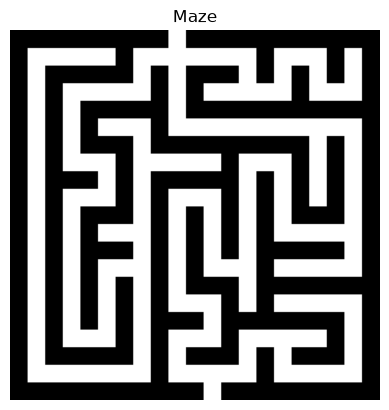

In [2]:
maze_image = plt.imread("maze(1).png")
print("Image shape:", maze_image.shape)
plt.imshow(maze_image, cmap="gray")
plt.title("Maze")
plt.axis("off")
plt.show()

### Setting the grid dimensions

The image is 210 × 210 pixels and contains 21 × 21 maze squares. Therefore, each square occupies 10 × 10 pixels.

In [3]:
maze_size = 21
square_size = 10

### Store walls and passages

I store the maze as a list within multiple lists where each list represents one row, with 1 for a wall and 0 for an open passage. This makes it easy to
check a square using maze[row][column].

The image is 210 × 210 pixels and the maze has 21 × 21 squares which means each square therefore occupies 10 × 10 pixels.

I use two nested for loops to build the grid where the outer loop goes through the rows, and the inner loop goes through the columns. For each square, the code reads its centre pixel.

An if/else statement decides whether the square is a wall or a passage. The code reads the red colour channel, where black is 0 and white is 1.
This means that a value below 0.5 is stored as a wall (1); otherwise, it is stored as a passage (0).

The append() method adds each value to the current row and once the inner loop finishes, the completed row is added to the maze.

The maze list is cleared before the loops so that running the cell again does not create duplicate rows which is why I then check that the grid
contains 21 rows and that every row contains 21 columns.

In [4]:
maze = []

for row in range(maze_size):
    maze_row = []

    for column in range(maze_size):
        pixel_row = row * square_size + square_size // 2
        pixel_column = column * square_size + square_size // 2

        pixel = maze_image[pixel_row, pixel_column, 0]

        if pixel < 0.5:
            maze_row.append(1)  # Wall
        else:
            maze_row.append(0)  # Passage

    maze.append(maze_row)

### Check the grid dimensions

Check that the grid contains 21 rows and that every row has 21 columns.

In [5]:
print("Number of rows:", len(maze))
print("Every row has 21 columns:",
      all(len(row) == maze_size for row in maze))

Number of rows: 21
Every row has 21 columns: True


### Display the maze as text

As mentioned earlier, I use two nested for loops to print the stored maze row by row. An if/else statement displays ## for a wall and two spaces for
an open passage and each square uses the same width to keep the columns aligned.

The end="" argument keeps the squares on the same line and after each row, print() starts a new line.

I initially displayed the stored values as 1 and 0, but found the layout difficult to read. Using wall symbols and spaces makes the passages easier to follow. This changes only the display and the maze still stores walls as 1 and passages as 0.

The text output provides a way to check the grid against the image before running either solver.

In [6]:
for row in maze:
    for square in row:
        if square == 1:
            print("##", end="")
        else:
            print("  ", end="")
    print()

##################  ######################
##          ##              ##      ##  ##
##  ##########  ##  ######  ##  ##  ##  ##
##  ##          ##  ##          ##      ##
##  ##  ##########  ######################
##  ##  ##      ##                      ##
##  ##  ######  ##################  ##  ##
##  ##      ##          ##      ##  ##  ##
##  ######  ##  ##########  ##  ##  ##  ##
##  ##      ##  ##      ##  ##  ##  ##  ##
##  ##  ######  ##  ##  ##  ##  ######  ##
##  ##  ##      ##  ##  ##  ##          ##
##  ##  ######  ##  ##  ##  ##########  ##
##  ##  ##      ##  ##      ##          ##
##  ##  ##  ##  ##  ######  ##############
##  ##  ##  ##  ##      ##  ##          ##
##  ##  ##  ##  ######  ##############  ##
##  ##      ##  ##      ##          ##  ##
##  ##########  ##  ######  ##  ######  ##
##              ##          ##          ##
######################  ##################


## Q1(b): Choose and run a solving approach

### Find the entrance and exit

The entrance is the open square in the top row, and the exit is the
open square in the bottom row. The maze has one opening in each of these rows.

I use maze[0] to access the first row and maze[-1] to access the last. The index(0) method finds the column containing the opening, because 0 represents an open passage.

Positions are stored as (row, column) tuples. Python indexes start at zero, giving an entrance of (0, 9) and an exit of (20, 11).

Finding these positions from the grid avoids the solvers entering their column numbers manually.

### Check valid positions

To check if the positions are valid, I use a function to check whether a position is inside the maze and is an open passage. Both solving algorithms use this function.

The if statements check the row and column boundaries first and If either is outside the grid, the function returns False.

If the position is inside the grid, the function checks its value. AS per the set up, A passage (0) returns True, and a wall (1) returns False.

I test the function with the entrance, a wall and a position outside the grid and the results are True, False and False, as expected.

In [7]:
entrance_column = maze[0].index(0)
exit_column = maze[-1].index(0)

entrance = (0, entrance_column)
exit_position = (len(maze) - 1, exit_column)

print("Entrance:", entrance)
print("Exit:", exit_position)

Entrance: (0, 9)
Exit: (20, 11)


In [8]:
def is_valid_position(maze, row, column):
    if row < 0 or row >= len(maze):
        return False

    if column < 0 or column >= len(maze[0]):
        return False

    return maze[row][column] == 0

In [9]:
print("Entrance:", is_valid_position(maze, 0, 9))
print("Wall:", is_valid_position(maze, 0, 0))
print("Outside grid:", is_valid_position(maze, -1, 9))

Entrance: True
Wall: False
Outside grid: False


Gives the expected result where the entrance is valid, the wall is invalid, and the position outside the grid is invalid.

### Defining the allowed movements

In [10]:
directions = [
    (1, 0),   # Down
    (0, 1),   # Right
    (-1, 0),  # Up
    (0, -1)   # Left
]

### Q1(b.ii): Backtracking and direction rationale

I use recursion and backtracking, where the function explores one square, then calls itself to explore the next square.

The directions are checked in the fixed order down, right, up, left. I check down first because the entrance is at the top and the exit is at the bottom which is convenient because it gives a consistent search order, but moving down does not always lead to the exit.

The function skips walls, positions outside the maze and squares already recorded in the visited list which prevents the search from repeatedly exploring the same squares.

The visited list stores every explored square and the path list stores the current route from the entrance.

Reaching the exit returns True and if all directions fail, path.pop() removes the current square from the route and the function returns False. The previous call then tries another direction which is essentially the backtracking step.

In [11]:
def solve_backtracking(maze, position, exit_position, visited, path):
    row, column = position

    if not is_valid_position(maze, row, column):
        return False
    if position in visited:
        return False

    visited.append(position)
    path.append(position)
    if position == exit_position:
        return True

    for row_change, column_change in directions:
        next_position = (row + row_change, column + column_change)

        if solve_backtracking(maze, next_position, exit_position,
                              visited, path):
            return True

    path.pop()  # No direction reached the exit so remove this square from the route.
    return False

In [12]:
visited = []
path = []
success = solve_backtracking(
    maze, entrance, exit_position, visited, path
)
print("Exit found:", success)
print("Squares visited:", len(visited))

if success:
    print("Movements in final route:", len(path) - 1)
    print("Route starts at:", path[0])
    print("Route ends at:", path[-1])
else:
    print("No route to the exit was found.")

Exit found: True
Squares visited: 75
Movements in final route: 62
Route starts at: (0, 9)
Route ends at: (20, 11)


### Check the backtracking result

The search explored 75 distinct squares and the final route contains 63 squares, requiring 62 movements from the entrance to the exit.

The visited list includes explored dead ends, while the path list contains only the successful route.

The following check confirms that every square in the route is an open passage and that each movement is one square horizontally or vertically.

In [13]:
valid_route = success

# Check that every square in the route is an open passage.
for row, column in path:
    if not is_valid_position(maze, row, column):
        valid_route = False

# Check each movement between consecutive squares.
for index in range(1, len(path)):
    previous_row, previous_column = path[index - 1]
    current_row, current_column = path[index]

    row_change = abs(current_row - previous_row)
    column_change = abs(current_column - previous_column)
    if row_change == 1 and column_change == 0:
        pass  # One square up or down
    elif row_change == 0 and column_change == 1:
        pass  # One square left or right
    else:
        valid_route = False

print("Route is valid:", valid_route)

Route is valid: True


That check passed. 

### Q1(b.i): Las Vegas and the 200-movement limit

I use the randomised approach where a for loop collects neighbouring open squares, and random.choice() selects the next position.

Unlike backtracking, this approach allows repeated visits and the visited list records these positions for the final plot.

A while loop limits each attempt to 200 movements and the function returns True if the exit is reached and False otherwise.
The final check includes reaching the exit on movement 200 so failure means the attempt did not reach the exit within the limit but it does not mean the maze has no solution.

In [14]:
def solve_las_vegas(maze, entrance, exit_position):
    position = entrance
    visited = [entrance]
    steps = 0

    while steps < 200:
        if position == exit_position:
            return True, visited, steps

        row, column = position
        possible_moves = []
        for row_change, column_change in directions:
            next_position = (row + row_change, column + column_change)

            if is_valid_position(maze, next_position[0], next_position[1]):
                possible_moves.append(next_position)

        if possible_moves == []:
            return False, visited, steps
        position = random.choice(possible_moves) # Allow revisits so the walk can move back out of dead ends
        visited.append(position)
        steps += 1

    return position == exit_position, visited, steps # Reaching the exit on movement 200 still counts as success.

In [15]:
lv_success, lv_visited, lv_steps = solve_las_vegas(
    maze, entrance, exit_position
)

print("Exit found:", lv_success)
print("Movements made:", lv_steps)
print("Final position:", lv_visited[-1])

Exit found: False
Movements made: 200
Final position: (6, 3)


### Check the Las Vegas attempt

Check that all visited positions are open passages and that each movement changes either the row or column by one square.

Also needs checking that the movement count matches the recorded walk and does not exceed 200.

In [16]:
wall_found = False
invalid_move = False

for row, column in lv_visited:
    if maze[row][column] == 1:
        wall_found = True

for index in range(1, len(lv_visited)):
    row, column = lv_visited[index]
    previous_row, previous_column = lv_visited[index - 1]
    distance = abs(row - previous_row) + abs(column - previous_column)
    if distance != 1:
        invalid_move = True

print("Wall entered:", wall_found)
print("Diagonal or invalid movement:", invalid_move)
print("Recorded movements:", len(lv_visited) - 1)
print("Reported movements:", lv_steps)
print("Within 200 movements:", lv_steps <= 200)
print("Final position:", lv_visited[-1])
print("Exit position:", exit_position)
print("Exit found:", lv_success)

Wall entered: False
Diagonal or invalid movement: False
Recorded movements: 200
Reported movements: 200
Within 200 movements: True
Final position: (6, 3)
Exit position: (20, 11)
Exit found: False


The recorded attempt entered no walls and used only one-square horizontal or vertical movements and the recorded and reported movement counts both equal 200.

The final position was not the exit, so False was the correct result and this confirms that the checks passed for this attempt.

The first attempt raised a NameError because random.choice() was used before the random module had been imported in.

Adding import random to the imports cell makes the module available.
    
Rerunning the import cell and it has worked.

This attempt stopped after 200 movements, reporting False because it hadn’t reached the exit which is an expected Las Vegas outcome.

Like with the backtracking test, it would be helpful to actually visualise the movement for the attempt. 
    
Therefore I've marked the visited squares in orange, even though this attempt did not reach the exit. 

Repeated visits appear at the same position on the plot.

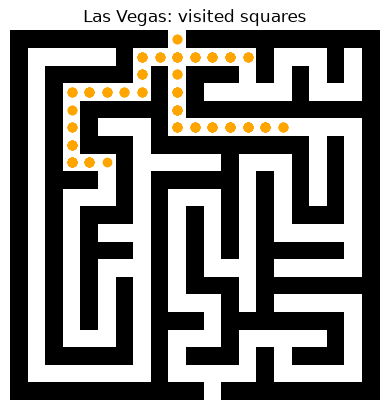

In [17]:
plt.imshow(maze, cmap="gray_r", vmin=0, vmax=1)

for row, column in lv_visited:
    plt.scatter(column, row, color="orange")
plt.title("Las Vegas: visited squares")
plt.axis("off")
plt.show()

### Select the solving approach

The input function asks the user to enter 1 for Backtracking or 2 for Las Vegas. I use 1 and 2 for simplicity.

A while loop repeats the question until a valid choice is entered and an if/else statement then runs the selected solver.

Each attempt uses fresh lists so earlier results do not affect the new search. The program then reports whether the exit was found and stores the visited positions for plotting.

In [18]:
choice = input("Enter 1 for Backtracking or 2 for Las Vegas: ")

while choice != "1" and choice != "2":
    choice = input("Please enter 1 or 2: ")
if choice == "1":
    chosen_visited = []
    chosen_path = []

    chosen_success = solve_backtracking(
        maze, entrance, exit_position, chosen_visited, chosen_path
    )
    title = "Backtracking: visited squares"
else:
    chosen_success, chosen_visited, chosen_steps = solve_las_vegas(
        maze, entrance, exit_position
    )
    title = "Las Vegas: visited squares"
    print("Movements made:", chosen_steps)

print("Exit found:", chosen_success)

Enter 1 for Backtracking or 2 for Las Vegas:  1


Exit found: True


## Q1(c): Visualise all visited squares

For visualisation as mentioned before, I use Matplotlib to display the maze. Walls are black and passages are white.

A for loop plots an orange dot at each visited position and columns give horizontal positions and rows give vertical positions.

The plots include explored dead ends and are displayed whether the attempt succeeds or fails. The repeated visits appear at the same position, so the plot shows where the solver went, rather than how often it visited each square.

### Backtracking visited squares

Display all squares explored by backtracking in orange,
including dead ends that are not part of the final route.

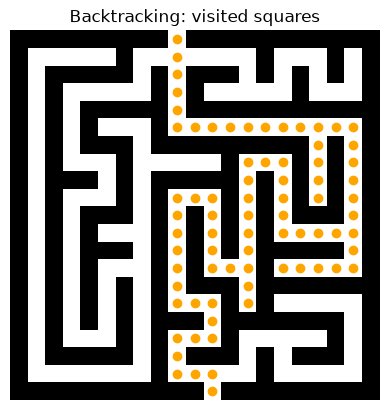

In [19]:
plt.imshow(maze, cmap="gray_r", vmin=0, vmax=1)

for row, column in visited:
    plt.scatter(column, row, color="orange")

plt.title("Backtracking: visited squares")
plt.axis("off")
plt.show()

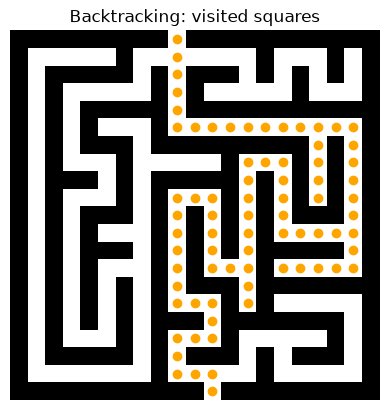

In [20]:
plt.imshow(maze, cmap="gray_r", vmin=0, vmax=1)

for row, column in chosen_visited:
    plt.scatter(column, row, color="orange")
plt.title(title)
plt.axis("off")
plt.show()

### Check the user interface and user choices

Entering 1 ran Backtracking and reported success and entering 2 ran Las Vegas, which stopped after 200 movements and reported failure for the recorded attempt.

Both choices displayed their visited squares and the invalid inputs caused the program to ask again for 1 or 2.

## Comparison (a): Differences between the approaches

The backtracking solver uses a fixed direction order and remembers which squares have been explored. When a route reaches a dead end, it returns to
an earlier square and tries another direction. It found the exit in every run on the supplied maze.

The Las Vegas approach chooses randomly from neighbouring open squares and it allows repeated visits, so movements can be spent exploring the same area. Each attempt stops at the exit or after 200 movements.

Backtracking searches systematically, while Las Vegas depends on random choices. A failed Las Vegas attempt does not show that there is no solution, only that the attempt did not reach it within the limit.

When compared with each other, the backtracking path is a valid route, but this approach does not generally guarantee the shortest route wheras the Las Vegas visited list
records the walk, including repeated positions.

## Comparison (b): Choice of data structures

As mentioned before, I use a list within mutliple lists to represent the maze's rows and columns where each square is accessed using maze[row][column], with 1 for a wall and 0 for a passage.

The tuples store positions as (row, column) and directions as changes in row and column.
 
For the backtracking solver, visited records explored squares and path stores the current route and the append() and pop() methods add squares to the route and remove them when backtracking.

For Las Vegas solver, possible_moves holds the available neighbouring squares and the visited list records each position in order, including repeats.

While the lists are simple to follow for this small maze, for larger mazes, a set would make checking previously visited positions faster.

## Comparison (c): Success rates over 10,000 runs

With the UI and both maze solver options working, they can be compared for their success rates over 10,000 runs

Need to run each algorithm 10,000 times on the same maze and count successful attempts. Each attempt starts with fresh visited and path lists.

Then can display the Success rate as a percentage, where is the number of successful attempts divided by the total number of attempts, multiplied by 100.

In [21]:
runs = 10000
backtracking_successes = 0

for attempt in range(runs):
    test_visited = []
    test_path = []
    result = solve_backtracking(
        maze, entrance, exit_position, test_visited, test_path
    )

    if result:
        backtracking_successes += 1

backtracking_rate = backtracking_successes / runs * 100
print("Successful backtracking runs:", backtracking_successes)
print("Backtracking success rate:", backtracking_rate, "%")

Successful backtracking runs: 10000
Backtracking success rate: 100.0 %


Backtracking succeeded in all 10,000 runs: 100% which is consistent with how the search works on this solvable maze.

For the Las Vegas solver it has to run 10,000 attempts on the same maze, with a limit of 200 movements per attempt and counts how many attempts reach the exit.

Random choices continue across attempts so perhaps the measured success rate may differ when the experiment is repeated.

In [22]:
runs = 10000
las_vegas_successes = 0

for attempt in range(runs):
    test_success, test_visited, test_steps = solve_las_vegas(
        maze, entrance, exit_position
    )

    if test_success:
        las_vegas_successes += 1

print("Successful runs:", las_vegas_successes)

Successful runs: 0


In [23]:
las_vegas_rate = las_vegas_successes / runs * 100

print("Las Vegas success rate:", las_vegas_rate, "%")

Las Vegas success rate: 0.0 %


### Check success detection on a small maze

The Las Vegas solver recorded no successes in the 10,000-run experiment so to check that it can recognise the exit, I use a separate small maze where the only available move leads directly to the target.

The expected result is True after one movement and this test does not change the maze experiment.

In [24]:
test_maze = [
    [1, 0, 1],
    [1, 0, 1],
    [1, 1, 1]
]

test_success, test_visited, test_steps = solve_las_vegas(
    test_maze, (0, 1), (1, 1)
)

print("Exit found:", test_success)
print("Movements:", test_steps)

Exit found: True
Movements: 1


The small-maze test returned True after one movement which confirms success detection for that test case, but does not check every possible outcome.

### Results and interpretation

| Algorithm | Successful attempts | Success rate |
|---|---:|---:|
| Backtracking | 10,000 out of 10,000 | 100% |
| Las Vegas | 0 out of 10,000 | 0% |

The backtracking solver uses a fixed direction order and returns to earlier squares when a route fails. It found the exit in every attempt.

The Las Vegas solver chooses moves randomly and can revisit squares however none of its 10,000 attempts reached the exit within 200 movements.

These results apply to this maze and these settings. A thing to note is that zero successful attempts does not mean Las Vegas can never succeed.

## Testing and bug reports

### Test 1: Duplicate rows when rerunning conversion

**Issue:** Running the conversion cell again added another 21 rows to the existing maze list. The dimension check showed 42 rows instead of 21.
The screenshot below shows the incorrect row count and duplicated maze output.

**Fix:** Move maze = [] into the start of the conversion cell, before the loops. This clears the previous grid on every run. This is important because both solvers need the correct maze dimensions where the duplicate rows change the grid being searched. I ran the conversion cell twice and checked the dimensions after each run. The grid remained at 21 rows, with 21 columns in every row.

![Grid incorrectly showing 42 rows](Screenshots/q1_duplicate_rows.png)

### Test 2: Missing random import

**Issue:** The Las Vegas solver raised a NameError when it reached random.choice(), because the random module had not been imported. The screenshot below shows the error message.

**Fix:** Add import random to the imports cell at the beginning of the notebook. The solver needs random.choice() to select a neighbouring open square. After running the imports cell, the attempt completed without the NameError and stopped after 200 movements.

![NameError caused by the missing random import](Screenshots/q1_missing_random.png)

### Test 3: Improve the maze's text display

**Issue:** The maze displayed correctly using 1 for walls and 0 for
passages, but I found it difficult to follow the maze layout. The before screenshot shows the numeric display and the after screenshot shows the clearer display using ## and spaces.

**Fix:** Use an if/else statement inside the printing loops to display ## for walls and two spaces for passages. The stored grid still uses 1 and 0. The clearer display makes it easier to compare the grid with the maze image. I ran the updated display cell and compared it with the maze image and the walls, passages, entrance and exit matched the image. The ## and space display made the layout easier for me to follow, while the stored grid remained unchanged.

![Numeric maze display before improvement](Screenshots/q1_readability_before.png)

![Clearer maze display after improvement](Screenshots/q1_readability_after.png)